# Training a multilayer perceptron from scratch, in JAX

Build an MLP out of nothing but arrays — the parameters, the forward pass, the optimizers, and the training
loop. `jax.grad` gives you backpropagation; write everything else yourself.

The target is a sum of four sine waves of **equal amplitude** at frequencies 1, 2, 4 and 8. 

In [1]:
# !pip install -q jax jaxlib matplotlib

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.11.2 | devices: [CpuDevice(id=0)]


## The data


In [2]:
FREQS = jnp.array([1.0, 2.0, 4.0, 8.0])
NOISE_STD = 0.02


def target_fn(x):
    """x: (n,) -> (n,)"""
    return jnp.mean(jnp.sin(2 * jnp.pi * FREQS * x[:, None]), axis=-1)


def make_data(key, n=2048, noise_std=NOISE_STD) -> list[jnp.array, jnp.array]:
    """Returns X: (n, 1), Y: (n, 1)"""
    key_x, key_noise = jax.random.split(key)
    x = jax.random.uniform(key_x, (n,), minval=0.0, maxval=1.0)
    y = target_fn(x) + noise_std * jax.random.normal(key_noise, (n,))
    return x[:, None], y[:, None]


SEED = jax.random.key(0)
X, Y = make_data(SEED) # key == PRNG seed

print(f"target variance : {float(Y.var()):.4f}")   # silly baseline: the error you get by predicting the mean

target variance : 0.1236


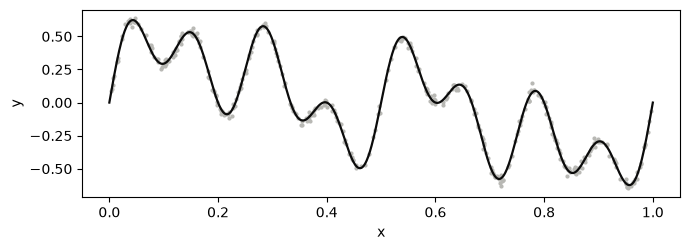

In [3]:
grid = jnp.linspace(0, 1, 1000)
plt.figure(figsize=(7, 2.6))
plt.scatter(np.array(X[:400, 0]), np.array(Y[:400, 0]), s=4, color="#b8b8b4")
plt.plot(np.array(grid), np.array(target_fn(grid)), color="#0b0b0b", lw=1.6)
plt.xlabel("x"); plt.ylabel("y"); plt.tight_layout(); plt.show()

---
## 1. The network

Write three functions:

- `init_mlp(key, layer_sizes)` — the parameters. Think about what a layer actually *is*, and about the scale
  of the initial random draw.
- `forward(params, x)` — `activation` on the hidden layers, nothing on the output.
- `loss_fn(params, x, y)` — mean squared error.

Use `[1, 128, 128, 1]`.

In [4]:
# layer1 = jnp.zeros(4)
# layer2 = jnp.zeros(8)
# print(f"l1: {layer1}")
# print(f"l2: {layer2}")
# l1_size = jnp.size(layer1, axis=0)
# l2_size = jnp.size(layer2, axis=0)
# print(f"l1 size: {l1_size}")
# print(f"l2 size: {l2_size}")
# bias1 = jnp.zeros((l1_size, l2_size))
# print(f"bias1: {bias1}")
# bias1_shape = (jnp.size(bias1, axis=0), jnp.size(bias1, axis=1))
# print(f"bias1 shape: {bias1_shape}")
prev_layer_size = 1
layer_size = 4
biases = jnp.zeros(layer_size) # biases of curr layer, expect (4,1)
# setup weight matrices (1 between consecutive layers, attending_layer rows x feeding_layer columns)
weights_arr = jnp.zeros((layer_size, prev_layer_size)) # weights of curr layer, expect (4, 1)
print(biases)
print(f"{'-' * 50}")
print(weights_arr)

[0. 0. 0. 0.]
--------------------------------------------------
[[0.]
 [0.]
 [0.]
 [0.]]


In [5]:
from abc import ABC, abstractmethod 

class MLP(ABC):
    key: jnp.array
    layer_sizes: list[int]
    weights: list[jnp.array] = []
    biases: list[jnp.array] = []

    def __init__(self, key, layer_sizes: list[int], fully_connected=True):
        self.key = key
        self.layer_sizes = layer_sizes

        self.__zero__(layer_sizes=layer_sizes)
        
        if not fully_connected:
            raise ValueError("Not fully connected MLPs are not supported.")

    def __zero__(self, layer_sizes):
        # Weights & Biases (shoutout) initialization
        self.biases = [0] * len(self.layer_sizes)
        self.weights = [0] * len(self.layer_sizes)
        prev_layer_size = 1
        for i, layer_size in enumerate(layer_sizes):  # x_next = sigmoid(Wx_in + b)
            self.biases[i] = jnp.zeros(layer_size)
            # setup weight matrices (1 between consecutive layers, attending_layer rows x feeding_layer columns)
            weights_arr = jnp.zeros((layer_size, prev_layer_size))
            prev_layer_size = layer_size
            self.weights[i] = weights_arr

    @abstractmethod
    def _weights_distribution(self, key: jnp.array, distribution: any, n_current: int, n_prev: int, mean: float) -> jnp.array:
        pass

    @abstractmethod
    def rand_initialize(self):
        # initialize random weights and biases
        pass

    @abstractmethod
    def activation(self, activation: any):
        # ie. sigmoid, relu, tanh independent of layer
        # ie. softmax (usually only last layer), relative to the whole row
        pass

    @abstractmethod
    def forward(self):
        # take input in and pass it through and see what output is
        pass
    
    # @abstractmethod
    # def loss(self):
    #     # compute loss jawn
    #     pass

    # @abstractmethod
    # def backprop(self):
    #     # use computed loss to update weights and biases
    #     pass

In [6]:
from enum import Enum

class Distributions(Enum):
    NORMAL = "NORMAL"
    XAVIER_NORMAL = "XAVIER_NORMAL"
    UNIFORM = "UNIFORM"

class Activations(Enum):
    RELU = "RELU"
    SIGMOID = "SIGMOID"
    TANH = "TANH"
    SOFTMAX = "SOFTMAX"

class MLP1(MLP):

    ########## INITIALIZATION ##########

    def uniform(self, key: jnp.array, n_current: int, n_prev: int, mean: float = 0) -> jnp.array:
        shape = (n_current, n_prev)
        weights = mean + jax.random.uniform(key=key, shape=shape)
        return weights

    def normal(self, key: jnp.array, n_current: int, n_prev: int, mean: float = 0) -> jnp.array:
        shape = (n_current, n_prev)
        weights = mean + jax.random.normal(key=key, shape=shape) * 1
        return weights

    def xavier_normal(self, key: jnp.array, n_current: int, n_prev: int, mean: float = 0) -> jnp.array:
        """
        internet gods said this is better for symmetric activation like sigmoid which I'm starting with.
        and easy to do, just scale variance by a relation of current layer + prev layer nodes
        """
        stddev = jnp.sqrt(2/(n_prev + n_current))
        shape = (n_current, n_prev)
        
        weights = mean + jax.random.normal(key=key, shape=shape) * stddev

        return weights

    def _weights_distribution(self, key: jnp.array, distribution: Distributions, n_current: int, n_prev: int, mean: float = 0) -> jnp.array:
        if distribution == Distributions.NORMAL:
            return self.normal(key=key, n_current=n_current, n_prev=n_prev, mean=mean)
        elif distribution == Distributions.XAVIER_NORMAL:
            return self.xavier_normal(key=key, n_current=n_current, n_prev=n_prev, mean=mean)
        elif distribution == Distributions.UNIFORM:
            return self.uniform(key=key, n_current=n_current, n_prev=n_prev, mean=mean)
        else:
            raise ValueError("Weights initialization distribution not supported!")

    def rand_initialize(self, bias_min: float = 0, bias_range: float = 0, weights_mean: float = 0, distribution: Distributions = Distributions.XAVIER_NORMAL):
        keys = jax.random.split(self.key, 2 * len(self.layer_sizes))

        for i, layer_size in enumerate(self.layer_sizes):
            key_b, key_w = keys[2*i], keys[2*i + 1]

            self.biases[i] = bias_min + bias_range * jax.random.uniform(
                key=key_b, 
                shape=(jnp.size(self.biases[i], axis=0), 1)
            ) # set up bias to be flexibly initializable

            # xavier normal draw for weights since we doin sigmoid shiz
            self.weights[i] = self._weights_distribution(
                key=key_w,
                n_current=jnp.size(self.weights[i], axis=0), 
                n_prev=jnp.size(self.weights[i], axis=1),
                mean=weights_mean,
                distribution=distribution
            )

    ########## ACTIVATIONS ##########

    def relu(self, x: jnp.array) -> jnp.array:
        return jnp.maximum(x, 0)

    def sigmoid(self, x: jnp.array) -> jnp.array:
        # == some shi
        return 1 / (1 + jnp.exp(-x))

    def tanh(self, x: jnp.array) -> jnp.array:
        return jnp.tanh(x)

    def softmax(self, x: jnp.array) -> jnp.array:
        raise ValueError("Not implemented yet!")

    def activation(self, x: jnp.array, activation: Activations = Activations.SIGMOID) -> jnp.array:
        if activation is Activations.RELU:
            return self.relu(x)
        elif activation is Activations.SIGMOID:
            return self.sigmoid(x)
        elif activation is Activations.TANH:
            return self.tanh(x)
        elif activation is Activations.SOFTMAX:
            return self.softmax(x)
        else:
            raise ValueError("Activation function not supported yet.")

    ########## FORWARD & LOSS ##########

    def forward(self, weights: jnp.array, biases: jnp.array, x: jnp.array, activation: Activations = Activations.SIGMOID) -> jnp.array:
        x_in = x.T
        
        # TODO: do we want to operate w the W_0 matrix and b_0 biases vector at the input node? it would make backprop easier I think... 
        # and I think sort of acts like a autoencoder for the input before the MLP does it's magic on it
        # TODO-2: do we want to save some intermediate computations for later optimization of backprop?

        for i, _ in enumerate(self.layer_sizes):
            x_in = weights[i] @ x_in + biases[i]
            if 0 < i < len(self.layer_sizes) - 1:
                x_in = self.activation(x_in, activation=activation)
        
        return x_in.T

    def loss(self, weights: jnp.array, biases: jnp.array, x: jnp.array, y: jnp.array) -> jnp.array:
        # MSE
        # x == inputs
        # MLP.forward(x) == output
        # y == expected
        y_theta = self.forward(weights, biases, x, activation=Activations.RELU)
        loss = jnp.mean(jnp.square(y - y_theta))
        
        return loss

In [7]:
a = jnp.array([1, -1, 0])
b = jnp.array([0, 0.5, -1])
loss = jnp.sum(jnp.square(a - b))
loss

Array(4.25, dtype=float32)

In [8]:
LAYER_SIZES = [1, 128, 128, 1]

def init_mlp(key, layer_sizes: list[int] = LAYER_SIZES) -> MLP1:
    """
    input 
        key: list[float] == RNG seed
        layer_size: list[int] == num nodes in each layer L->R
    
    returns
        network: discretionary repr. of the network
            I think if we're avoiding package classes, we can repr this as:
                weights: list[array] == 4 rank-2 tensors / 2-D arrays -- one per layer->layer interface (row == per node attending weights).
                    pros: not storing massive square (1+128+128+1)^2 matrix which is mostly 0's
                    cons: different sizes

                biases: list[array] == 4 rank-1 -- one per layer
                    cons: diff sizes
    """
    mlp = MLP1(
        key=key,
        layer_sizes=layer_sizes,
        fully_connected=True
    )

    mlp.rand_initialize(distribution=Distributions.XAVIER_NORMAL)

    return mlp

def forward(params: MLP1, x) -> jnp.array:
    mlp = params
    y = mlp.forward(mlp.weights, mlp.biases, x, activation=Activations.RELU)
    return y

def loss_fn(params: MLP1, x, y) -> jnp.array:
    mlp = params
    loss = mlp.loss(mlp.weights, mlp.biases, x, y)
    return loss


In [9]:
# seed = jax.random.key(0)
mlp = init_mlp(key=SEED, layer_sizes=[1,2,1])
print(mlp.biases)
print(f"{'-'*50}")
print(mlp.weights) # TODO: fuck. for some reason initialized weights for L3 are the stacked L2 weights... ball sacks

[Array([[0.]], dtype=float32), Array([[0.],
       [0.]], dtype=float32), Array([[0.]], dtype=float32)]
--------------------------------------------------
[Array([[-2.4424558]], dtype=float32), Array([[-0.5078148 ],
       [ 0.51015043]], dtype=float32), Array([[0.52041626, 0.2609454 ]], dtype=float32)]


In [10]:
forward(mlp, jnp.array([1]))

Array([[0.6454802]], dtype=float32)

In [11]:
loss_fn(mlp, jnp.array([1]), jnp.array([1]))

Array(0.12568428, dtype=float32)

---
## 3. The optimizers

Implement each one from its update equation:

1. **Gradient descent** — full batch, one step per epoch
2. **SGD** — minibatch
3. **SGD with momentum**
4. **Adagrad**
5. **Adam**
6. **Muon** — if you get that far, but it is waaaay trickier so don't get discouraged if you stop at Adam!

Look the update rules up. Muon is recent and not in textbooks:
[kellerjordan.github.io/posts/muon](https://kellerjordan.github.io/posts/muon/).

In [68]:
def gd(mlp: MLP1, grads_w: jnp.array, grads_b: jnp.array, lr: float) -> None:
    for i in range(len(mlp.weights)):
        mlp.weights[i] = mlp.weights[i] - lr * grads_w[i]
        mlp.biases[i] = mlp.biases[i] - lr * grads_b[i]
    
    return


def sgd(mlp: MLP1, grads_w: jnp.array, grads_b: jnp.array, lr: float) -> None:
    for i in range(len(mlp.weights)):
        mlp.weights[i] = mlp.weights[i] - lr * grads_w[i]
        mlp.biases[i] = mlp.biases[i] - lr * grads_b[i]
    
    return


class SGDM:
    beta: float
    m_w: jnp.array
    m_b: jnp.array

    def __init__(
        self,
        beta: float =0.9
    ):
        self.beta = beta
        self.m_w = None
        self.m_b = None

    def __call__(
        self,
        mlp: MLP1,
        grads_w: jnp.array,
        grads_b: jnp.array,
        lr: float
    ):
        if self.m_w is None:
            self.m_w = [jnp.zeros_like(g) for g in grads_w]
            self.m_b = [jnp.zeros_like(g) for g in grads_b]
        
        for i in range(len(mlp.weights)):
            self.m_w[i] = self.beta * self.m_w[i] + (1 - self.beta) * grads_w[i]
            self.m_b[i] = self.beta * self.m_b[i] + (1 - self.beta) * grads_b[i]

            mlp.weights[i] = mlp.weights[i] - lr * self.m_w[i]
            mlp.biases[i] = mlp.biases[i] - lr * self.m_b[i]

class Adagrad:
    def __init__(self, eps: float = 1e-8):
        self.eps = eps
        self.s_w = None   # running sum of squared gradients, one entry per weight
        self.s_b = None

    def __call__(self, mlp: MLP1, grads_w, grads_b, lr: float):
        if self.s_w is None:
            self.s_w = [jnp.zeros_like(g) for g in grads_w]
            self.s_b = [jnp.zeros_like(g) for g in grads_b]

        for i in range(len(mlp.weights)):
            self.s_w[i] = self.s_w[i] + grads_w[i] ** 2
            self.s_b[i] = self.s_b[i] + grads_b[i] ** 2

            mlp.weights[i] = mlp.weights[i] - lr * grads_w[i] / (jnp.sqrt(self.s_w[i]) + self.eps)
            mlp.biases[i] = mlp.biases[i] - lr * grads_b[i] / (jnp.sqrt(self.s_b[i]) + self.eps)

class Adam:
    def __init__(self, beta1: float = 0.9, beta2: float = 0.999, eps: float = 1e-8):
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.m_w = None   # moving average of gradients, momentum's m
        self.m_b = None
        self.s_w = None   # moving average of squared gradients, the per-weight scale
        self.s_b = None
        self.t = 0        # step counter for bias correction

    def __call__(self, mlp: MLP1, grads_w, grads_b, lr: float):
        if self.m_w is None:
            self.m_w = [jnp.zeros_like(g) for g in grads_w]
            self.m_b = [jnp.zeros_like(g) for g in grads_b]
            self.s_w = [jnp.zeros_like(g) for g in grads_w]
            self.s_b = [jnp.zeros_like(g) for g in grads_b]

        self.t += 1   # once per step, not once per layer
        correction_m = 1 - self.beta1 ** self.t
        correction_s = 1 - self.beta2 ** self.t

        for i in range(len(mlp.weights)):
            self.m_w[i] = self.beta1 * self.m_w[i] + (1 - self.beta1) * grads_w[i]
            self.m_b[i] = self.beta1 * self.m_b[i] + (1 - self.beta1) * grads_b[i]
            self.s_w[i] = self.beta2 * self.s_w[i] + (1 - self.beta2) * grads_w[i] ** 2
            self.s_b[i] = self.beta2 * self.s_b[i] + (1 - self.beta2) * grads_b[i] ** 2

            m_hat_w = self.m_w[i] / correction_m
            m_hat_b = self.m_b[i] / correction_m
            s_hat_w = self.s_w[i] / correction_s
            s_hat_b = self.s_b[i] / correction_s

            mlp.weights[i] = mlp.weights[i] - lr * m_hat_w / (jnp.sqrt(s_hat_w) + self.eps)
            mlp.biases[i] = mlp.biases[i] - lr * m_hat_b / (jnp.sqrt(s_hat_b) + self.eps)

---
## 2. The training loop

Minibatches of 128, reshuffled every epoch, 400 epochs. Get gradients with `jax.grad`. Wrap the step in
`@jax.jit` or it will be slow.

In [95]:
import time

mlp = init_mlp(key=SEED, layer_sizes=LAYER_SIZES)
n = len(X)
n_train = int(0.8 * n)
n_val = int(0.9 * n)

# X, Y
train_x = X[:n_train]
val_x = X[n_train:n_val]
test_x = X[n_val:]

train_labels = Y[:n_train]
val_labels = Y[n_train:n_val]
test_labels = Y[n_val:]

# HYPERPARAMETERS
EPOCHS = 400
MINIBATCH_SIZE = 128 # jnp.size(train, axis=0)
LR = 0.001

# loss and gradients compiled once per mlp and minibatch shape
loss_and_grads = jax.jit(jax.value_and_grad(MLP1.loss, argnums=(1, 2)), static_argnums=0)

def step(minibatch: jnp.array, labels: jnp.array, mlp: MLP1,  optimizer: callable = gd, lr: float = LR) -> float:
    """
    returns 
        loss: float

    updates mlp weights
    """
    loss, (grads_w, grads_b) = loss_and_grads(mlp, mlp.weights, mlp.biases, minibatch, labels)
    optimizer(mlp=mlp, grads_w=grads_w, grads_b=grads_b, lr=lr)
    return loss

def train(optimizer: callable, lr: float = LR, epochs: int = EPOCHS, minibatch_size: int = MINIBATCH_SIZE, key: jnp.array = SEED, log_every: int = 25) -> list[MLP1, jnp.array, jnp.array, jnp.array, jnp.array]:
    mlp = init_mlp(key=key, layer_sizes=LAYER_SIZES)
    keys = jax.random.split(key, epochs) # for shuffling minibatch sampling
    step_losses: list[float] = []
    epoch_losses: list[float] = []
    val_losses: list[float] = []
    step_times: list[float] = []

    for epoch in range(epochs):
        indices: jnp.array = jax.random.permutation(key=keys[epoch], x=jnp.array(range(n_train)))
        losses = []

        for start in range(0, n_train, minibatch_size):
            minibatch_mask: jnp.array = indices[start:start + minibatch_size]
            minibatch: jnp.array = train_x[minibatch_mask]
            labels: jnp.array = train_labels[minibatch_mask]

            t0 = time.perf_counter()
            loss: float = step(
                minibatch=minibatch,
                labels=labels,
                mlp=mlp,
                optimizer=optimizer,
                lr=lr
            )
            jax.block_until_ready((loss, mlp.weights, mlp.biases))   # JAX runs async; wait for the real work
            step_times.append(time.perf_counter() - t0)

            losses.append(loss)

        step_losses.extend(losses)
        epoch_losses.append(jnp.mean(jnp.array(losses)))

        val_loss = loss_fn(params=mlp, x=val_x, y=val_labels)
        val_losses.append(val_loss)

        if epoch % log_every == 0:
            print(f"epoch {epoch}: train loss {jnp.mean(jnp.array(losses))} & val loss: {val_loss}")

    return mlp, step_losses, epoch_losses, val_losses, jnp.median(jnp.array(step_times))

In [96]:
print(f"\n{'-'*50} GD TRAINING {'-'*50}")
mlp_gd, step_losses_gd, epoch_losses_gd, val_losses_gd, step_time_gd = train(
    optimizer=gd,
    lr=LR,
    epochs=EPOCHS,
    minibatch_size=n_train,
    key=SEED,
    log_every=25
)


-------------------------------------------------- GD TRAINING --------------------------------------------------
epoch 0: train loss 0.11579841375350952 & val loss: 0.11864236742258072
epoch 25: train loss 0.11315041780471802 & val loss: 0.11571478843688965
epoch 50: train loss 0.11078514903783798 & val loss: 0.11313477158546448
epoch 75: train loss 0.10862046480178833 & val loss: 0.11080092191696167
epoch 100: train loss 0.10660591721534729 & val loss: 0.10865113884210587
epoch 125: train loss 0.10471730679273605 & val loss: 0.10665206611156464
epoch 150: train loss 0.10293318331241608 & val loss: 0.10477326810359955
epoch 175: train loss 0.1012410968542099 & val loss: 0.10299801826477051
epoch 200: train loss 0.09963145852088928 & val loss: 0.10131130367517471
epoch 225: train loss 0.09809718281030655 & val loss: 0.09970556199550629
epoch 250: train loss 0.09663239866495132 & val loss: 0.0981743261218071
epoch 275: train loss 0.09523560106754303 & val loss: 0.09671315550804138
epoc

In [97]:
print(f"\n{'-'*50} SGD TRAINING {'-'*50}")
mlp_sgd, step_losses_sgd, epoch_losses_sgd, val_losses_sgd, step_time_sgd = train(
    optimizer=sgd,
    lr=LR,
    epochs=EPOCHS,
    minibatch_size=MINIBATCH_SIZE,
    key=SEED,
    log_every=25
)


-------------------------------------------------- SGD TRAINING --------------------------------------------------
epoch 0: train loss 0.11519116908311844 & val loss: 0.11719328910112381
epoch 25: train loss 0.09258455783128738 & val loss: 0.09335607290267944
epoch 50: train loss 0.0798296108841896 & val loss: 0.08024574816226959
epoch 75: train loss 0.07197362929582596 & val loss: 0.07203808426856995
epoch 100: train loss 0.06703993678092957 & val loss: 0.06677050143480301
epoch 125: train loss 0.06391117721796036 & val loss: 0.06337254494428635
epoch 150: train loss 0.06194133684039116 & val loss: 0.06111873686313629
epoch 175: train loss 0.06069951876997948 & val loss: 0.05965837091207504
epoch 200: train loss 0.06008564308285713 & val loss: 0.05870837718248367
epoch 225: train loss 0.0595717690885067 & val loss: 0.0580814927816391
epoch 250: train loss 0.05898050218820572 & val loss: 0.05764593556523323
epoch 275: train loss 0.05879176780581474 & val loss: 0.05735168606042862
epoc

In [98]:
print(f"\n{'-'*50} SGDM TRAINING {'-'*50}")
mlp_sgdm, step_losses_sgdm, epoch_losses_sgdm, val_losses_sgdm, step_time_sgdm = train(
    optimizer=SGDM(),
    lr=LR,
    epochs=EPOCHS,
    minibatch_size=MINIBATCH_SIZE,
    key=SEED,
    log_every=25
)


-------------------------------------------------- SGDM TRAINING --------------------------------------------------
epoch 0: train loss 0.11560513079166412 & val loss: 0.1179850697517395
epoch 25: train loss 0.0929073691368103 & val loss: 0.09368380904197693
epoch 50: train loss 0.07996228337287903 & val loss: 0.08039822429418564
epoch 75: train loss 0.07203127443790436 & val loss: 0.07209421694278717
epoch 100: train loss 0.0670553594827652 & val loss: 0.06678227335214615
epoch 125: train loss 0.06390827894210815 & val loss: 0.0633639395236969
epoch 150: train loss 0.06193160265684128 & val loss: 0.06110629066824913
epoch 175: train loss 0.06068393960595131 & val loss: 0.05964474752545357
epoch 200: train loss 0.06007339060306549 & val loss: 0.05870012566447258
epoch 225: train loss 0.05955949053168297 & val loss: 0.058066464960575104
epoch 250: train loss 0.05897171050310135 & val loss: 0.057641323655843735
epoch 275: train loss 0.05878697708249092 & val loss: 0.05734621733427048
ep

In [99]:
print(f"\n{'-'*50} Adagrad TRAINING {'-'*50}")
mlp_adagrad, step_losses_adagrad, epoch_losses_adagrad, val_losses_adagrad, step_time_adagrad = train(
    optimizer=Adagrad(),
    lr=LR,
    epochs=EPOCHS,
    minibatch_size=MINIBATCH_SIZE,
    key=SEED,
    log_every=25
)


-------------------------------------------------- Adagrad TRAINING --------------------------------------------------
epoch 0: train loss 0.10193724185228348 & val loss: 0.0978371798992157
epoch 25: train loss 0.0603155642747879 & val loss: 0.058593884110450745
epoch 50: train loss 0.05818169191479683 & val loss: 0.05662974715232849
epoch 75: train loss 0.05743749067187309 & val loss: 0.05600704997777939
epoch 100: train loss 0.05705824866890907 & val loss: 0.055946774780750275
epoch 125: train loss 0.05670579895377159 & val loss: 0.055666711181402206
epoch 150: train loss 0.05648241192102432 & val loss: 0.055578846484422684
epoch 175: train loss 0.05631398782134056 & val loss: 0.055408772081136703
epoch 200: train loss 0.056295547634363174 & val loss: 0.055331043899059296
epoch 225: train loss 0.056177396327257156 & val loss: 0.055334918200969696
epoch 250: train loss 0.055793337523937225 & val loss: 0.05524728447198868
epoch 275: train loss 0.05573941022157669 & val loss: 0.0552291

In [100]:
print(f"\n{'-'*50} Adam TRAINING {'-'*50}")
mlp_adam, step_losses_adam, epoch_losses_adam, val_losses_adam, step_time_adam = train(
    optimizer=Adam(),
    lr=LR,
    epochs=EPOCHS,
    minibatch_size=MINIBATCH_SIZE,
    key=SEED,
    log_every=25
)


-------------------------------------------------- Adam TRAINING --------------------------------------------------
epoch 0: train loss 0.0992565006017685 & val loss: 0.08736532926559448
epoch 25: train loss 0.05963071808218956 & val loss: 0.059787094593048096
epoch 50: train loss 0.0564706027507782 & val loss: 0.05637461319565773
epoch 75: train loss 0.05739616975188255 & val loss: 0.05644962936639786
epoch 100: train loss 0.05436030030250549 & val loss: 0.05549382045865059
epoch 125: train loss 0.049050383269786835 & val loss: 0.050779398530721664
epoch 150: train loss 0.042121537029743195 & val loss: 0.04391758143901825
epoch 175: train loss 0.03653213754296303 & val loss: 0.037678416818380356
epoch 200: train loss 0.03394320234656334 & val loss: 0.03454439714550972
epoch 225: train loss 0.03221115842461586 & val loss: 0.033691711723804474
epoch 250: train loss 0.03145037591457367 & val loss: 0.0321248359978199
epoch 275: train loss 0.03239135444164276 & val loss: 0.032150037586688

---
## 4. What to report

- **All six loss curves on one set of axes**, log scale on y. Plot against both epochs and steps

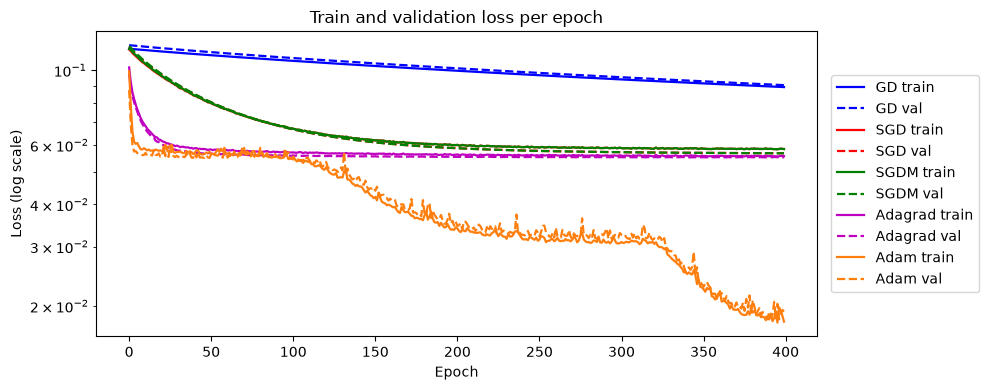

In [101]:
COLORS = {"GD": "b", "SGD": "r", "SGDM": "g", "Adagrad": "m", "Adam": "tab:orange"}
runs = {
    "GD": (step_losses_gd, epoch_losses_gd, val_losses_gd),
    "SGD": (step_losses_sgd, epoch_losses_sgd, val_losses_sgd),
    "SGDM": (step_losses_sgdm, epoch_losses_sgdm, val_losses_sgdm),
    "Adagrad": (step_losses_adagrad, epoch_losses_adagrad, val_losses_adagrad),
    "Adam": (step_losses_adam, epoch_losses_adam, val_losses_adam),
}

plt.figure(figsize=(10, 4))
for name, (_, epoch_losses, val_losses) in runs.items():
    plt.plot(epoch_losses, color=COLORS[name], lw=1.6, label=f"{name} train")
    plt.plot(val_losses, color=COLORS[name], lw=1.6, ls="--", label=f"{name} val")
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.title('Train and validation loss per epoch')
plt.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', borderaxespad=0.)
plt.tight_layout(); plt.show()

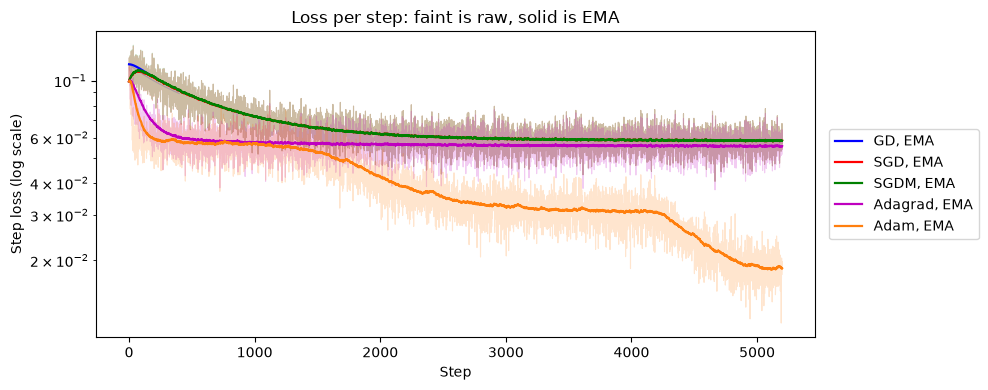

In [102]:
def ema(values, beta=0.98):
    """Exponential moving average: the same smoother as momentum's m."""
    smoothed = []
    m = values[0]
    for v in values:
        m = beta * m + (1 - beta) * v
        smoothed.append(m)
    return jnp.array(smoothed)

plt.figure(figsize=(10, 4))
for name, (step_losses, _, _) in runs.items():
    plt.plot(step_losses, color=COLORS[name], lw=0.8, alpha=0.2, zorder=1)
    plt.plot(ema(step_losses), color=COLORS[name], lw=1.6, label=f"{name}, EMA")
plt.yscale('log')
plt.xlabel('Step')
plt.ylabel('Step loss (log scale)')
plt.title('Loss per step: faint is raw, solid is EMA')
plt.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', borderaxespad=0.)
plt.tight_layout(); plt.show()

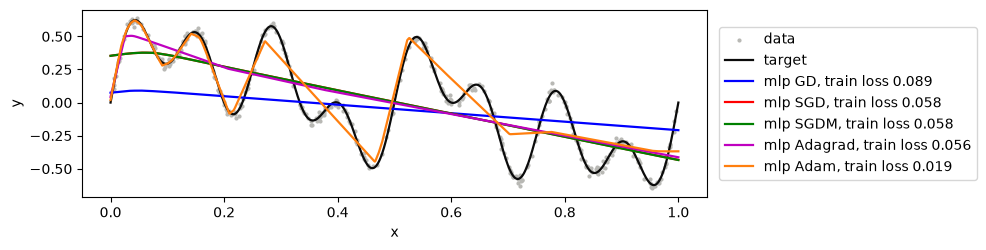

In [103]:
grid = jnp.linspace(0, 1, 1000)
pred_gd = forward(mlp_gd, grid[:, None])[:, 0]
pred_sgd = forward(mlp_sgd, grid[:, None])[:, 0]
pred_sgdm = forward(mlp_sgdm, grid[:, None])[:, 0]
pred_adagrad = forward(mlp_adagrad, grid[:, None])[:, 0]
pred_adam = forward(mlp_adam, grid[:, None])[:, 0]

plt.figure(figsize=(10, 2.6))
plt.scatter(X[:400, 0], Y[:400, 0], s=4, color="#b8b8b4", label="data")
plt.plot(grid, target_fn(grid), color="#0b0b0b", lw=1.6, label="target")
plt.plot(grid, pred_gd, color="b", lw=1.6,
         label=f"mlp GD, train loss {float(loss_fn(mlp_gd, train_x, train_labels)):.3f}")
plt.plot(grid, pred_sgd, color="r", lw=1.6,
         label=f"mlp SGD, train loss {float(loss_fn(mlp_sgd, train_x, train_labels)):.3f}")
plt.plot(grid, pred_sgdm, color="g", lw=1.6,
         label=f"mlp SGDM, train loss {float(loss_fn(mlp_sgdm, train_x, train_labels)):.3f}")
plt.plot(grid, pred_adagrad, color="m", lw=1.6,
         label=f"mlp Adagrad, train loss {float(loss_fn(mlp_adagrad, train_x, train_labels)):.3f}")
plt.plot(grid, pred_adam, color="tab:orange", lw=1.6,
         label=f"mlp Adam, train loss {float(loss_fn(mlp_adam, train_x, train_labels)):.3f}")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', borderaxespad=0.)
plt.tight_layout(); plt.show()

---
## 5. One more plot

Now make a plot I did not ask for.



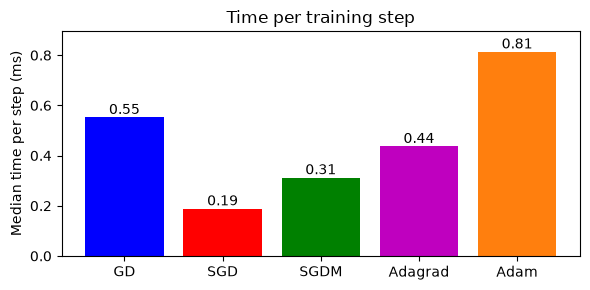

In [104]:
time_per_step = {"GD": step_time_gd, "SGD": step_time_sgd, "SGDM": step_time_sgdm,
                 "Adagrad": step_time_adagrad, "Adam": step_time_adam}

plt.figure(figsize=(6, 3))
bars = plt.bar(list(time_per_step), [1000 * t for t in time_per_step.values()],
               color=[COLORS[name] for name in time_per_step])
plt.bar_label(bars, fmt="%.2f")
plt.margins(y=0.1)   # headroom so the tallest label clears the frame
plt.ylabel("Median time per step (ms)")
plt.title("Time per training step")
plt.tight_layout(); plt.show()